# Tutorial 12: Basic Autoencoders in PyTorch

## Block 1: Import libraries

In [1]:
import time
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(42)
print('Device:', device)

Device: cuda


## Block 2: Load data set

In [2]:
# Load the dataset (MNIST)
train_set = datasets.MNIST(root='./data', train=True, download=True)
test_set = datasets.MNIST(root='./data', train=False, download=True)
x_train = train_set.data.float() / 255.
x_test = test_set.data.float() / 255.

# Add an extra dimension for the channel (since MNIST is grayscale).
# PyTorch puts the channel first: (N, 1, 28, 28) instead of Keras' (N, 28, 28, 1)
x_train = x_train.unsqueeze(1)
x_test = x_test.unsqueeze(1)

print('x_train:', tuple(x_train.shape), '| x_test:', tuple(x_test.shape))
print('Pixel values from', x_train.min().item(), 'to', x_train.max().item())

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 400kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.76MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.4MB/s]


x_train: (60000, 1, 28, 28) | x_test: (10000, 1, 28, 28)
Pixel values from 0.0 to 1.0


## Block 3: Define the autoencoder model

In [3]:
class Autoencoder(nn.Module):
    # The tutorial's convolutional autoencoder
    def __init__(self):
        super().__init__()
        # Encoder part
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),                            # 28x28 -> 14x14
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2)                             # 14x14 -> 7x7: encoded = 64 x 7 x 7
        )
        # Decoder part
        self.decoder = nn.Sequential(
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2),                # 7x7 -> 14x14 (Keras UpSampling2D)
            nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2),                # 14x14 -> 28x28
            nn.Conv2d(32, 1, 3, padding=1), nn.Sigmoid()
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


def summary(model):
    # Output shape and parameters of every layer, like Keras' model.summary()
    rows, hooks = [], []

    def hook(module, inputs, output):
        rows.append((module.__class__.__name__, tuple(output.shape), sum(p.numel() for p in module.parameters())))

    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.MaxPool2d, nn.Upsample, nn.Linear)):
            hooks.append(m.register_forward_hook(hook))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 1, 28, 28, device=next(model.parameters()).device))
    model.train(was_training)
    for h in hooks:
        h.remove()
    print(f"{'Layer':16} {'Output shape':>18} {'Params':>10}")
    for name, shape, params in rows:
        print(f"{name:16} {str(shape):>18} {params:10,}")
    print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")


def latent_size(model):
    with torch.no_grad():
        model.eval()
        return model.encoder(torch.zeros(1, 1, 28, 28, device=next(model.parameters()).device)).numel()


autoencoder = Autoencoder().to(device)
summary(autoencoder)
print(f'Latent representation: {latent_size(autoencoder):,} numbers for a 28x28 = 784 pixel image')

Layer                  Output shape     Params
Conv2d              (1, 32, 28, 28)        320
MaxPool2d           (1, 32, 14, 14)          0
Conv2d              (1, 64, 14, 14)     18,496
MaxPool2d             (1, 64, 7, 7)          0
Conv2d                (1, 64, 7, 7)     36,928
Upsample            (1, 64, 14, 14)          0
Conv2d              (1, 32, 14, 14)     18,464
Upsample            (1, 32, 28, 28)          0
Conv2d               (1, 1, 28, 28)        289
Total parameters: 74,497
Latent representation: 3,136 numbers for a 28x28 = 784 pixel image


## Block 4: Train the autoencoder

In [4]:
def evaluate(model, x, batch_size=1000):
    # Binary cross-entropy (the training loss), mean squared error and PSNR of the reconstructions
    model.eval()
    bce, mse, psnr = 0.0, 0.0, 0.0
    with torch.no_grad():
        for k in range(0, len(x), batch_size):
            xb = x[k:k + batch_size].to(device)
            out = model(xb)
            bce += F.binary_cross_entropy(out, xb, reduction='sum').item()
            per_image = ((out - xb) ** 2).flatten(1).mean(1)
            mse += per_image.sum().item()
            psnr += (10 * torch.log10(1 / per_image.clamp(min=1e-10))).sum().item()
    n = len(x)
    return {'bce': bce / (n * 784), 'mse': mse / n, 'psnr': psnr / n}


def train(model, epochs=50, batch_size=128, lr=1e-3, print_every=1):
    # Adam with the Keras default learning rate (0.001) and binary cross-entropy, as in the tutorial
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    xtr = x_train.to(device)
    history = {'loss': [], 'val_loss': []}
    start = time.time()
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(xtr), device=device)  # shuffle=True
        total = 0.0
        for k in range(0, len(xtr), batch_size):
            xb = xtr[order[k:k + batch_size]]
            loss = F.binary_cross_entropy(model(xb), xb)  # the input is also the target
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        val = evaluate(model, x_test)
        history['loss'].append(total / len(xtr))
        history['val_loss'].append(val['bce'])
        if epoch == 0 or (epoch + 1) % print_every == 0:
            print(f"Epoch {epoch + 1}/{epochs} - loss: {history['loss'][-1]:.4f} - val_loss: {val['bce']:.4f}")
    history['time'] = time.time() - start
    return history


# Train the autoencoder
history = train(autoencoder, epochs=50, batch_size=128)
print(f"Training time: {history['time']:.1f} s")

Epoch 1/50 - loss: 0.1121 - val_loss: 0.0750
Epoch 2/50 - loss: 0.0725 - val_loss: 0.0703
Epoch 3/50 - loss: 0.0700 - val_loss: 0.0686
Epoch 4/50 - loss: 0.0687 - val_loss: 0.0680
Epoch 5/50 - loss: 0.0678 - val_loss: 0.0672
Epoch 6/50 - loss: 0.0671 - val_loss: 0.0662
Epoch 7/50 - loss: 0.0666 - val_loss: 0.0658
Epoch 8/50 - loss: 0.0661 - val_loss: 0.0654
Epoch 9/50 - loss: 0.0657 - val_loss: 0.0651
Epoch 10/50 - loss: 0.0654 - val_loss: 0.0653
Epoch 11/50 - loss: 0.0651 - val_loss: 0.0647
Epoch 12/50 - loss: 0.0648 - val_loss: 0.0644
Epoch 13/50 - loss: 0.0646 - val_loss: 0.0642
Epoch 14/50 - loss: 0.0644 - val_loss: 0.0639
Epoch 15/50 - loss: 0.0643 - val_loss: 0.0637
Epoch 16/50 - loss: 0.0641 - val_loss: 0.0636
Epoch 17/50 - loss: 0.0640 - val_loss: 0.0637
Epoch 18/50 - loss: 0.0639 - val_loss: 0.0634
Epoch 19/50 - loss: 0.0637 - val_loss: 0.0633
Epoch 20/50 - loss: 0.0636 - val_loss: 0.0633
Epoch 21/50 - loss: 0.0635 - val_loss: 0.0631
Epoch 22/50 - loss: 0.0635 - val_loss: 0.06

## Block 5: Visualize the results

Test loss (binary cross-entropy): 0.0620 | MSE: 0.00089 | PSNR: 31.14 dB


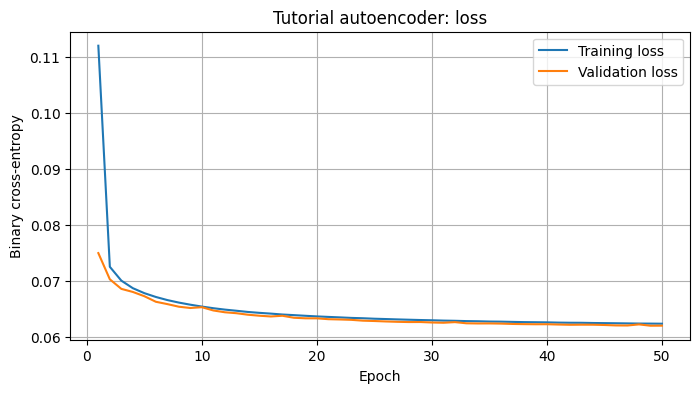

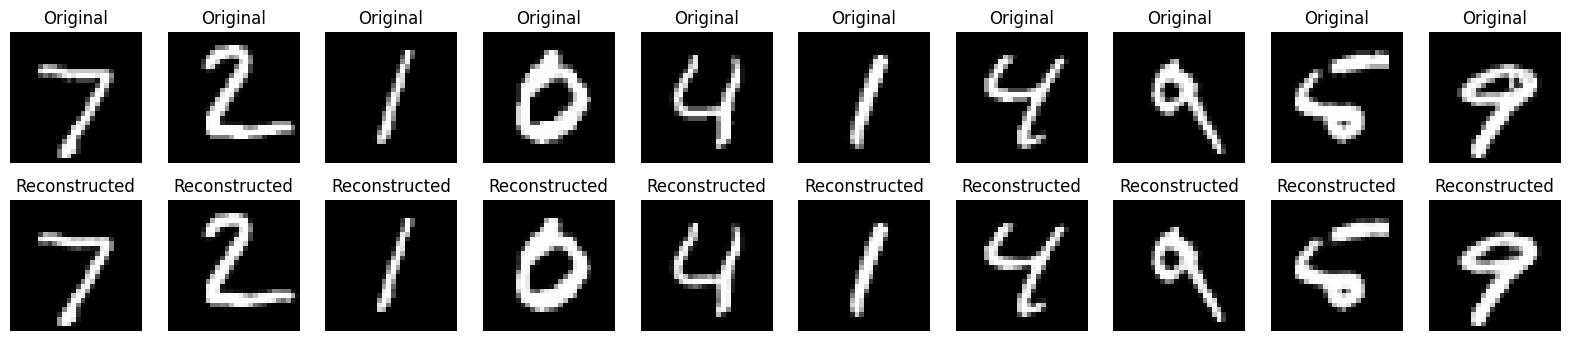

In [5]:
def predict(model, x, batch_size=1000):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(x[k:k + batch_size].to(device)).cpu() for k in range(0, len(x), batch_size)])


scores = evaluate(autoencoder, x_test)
print(f"Test loss (binary cross-entropy): {scores['bce']:.4f} | MSE: {scores['mse']:.5f} | PSNR: {scores['psnr']:.2f} dB")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(history['loss']) + 1), history['loss'], label='Training loss')
plt.plot(range(1, len(history['val_loss']) + 1), history['val_loss'], label='Validation loss')
plt.title('Tutorial autoencoder: loss')
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy')
plt.legend()
plt.grid()
plt.show()

decoded_imgs = predict(autoencoder, x_test[:10])

# Visualize the original and reconstructed images side by side
n = 10  # How many digits we will display
plt.figure(figsize=(20, 4))
for i in range(n):
    # Display original image
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
    plt.title("Original")

    # Display reconstructed image
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
    plt.title("Reconstructed")

plt.show()

## Block 6: Task - Define different autoencoder architectures

In [6]:
class DenseAE(nn.Module):
    # Basic fully connected autoencoder: 784 -> 256 -> 128 -> latent -> 128 -> 256 -> 784
    def __init__(self, latent_dim=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, latent_dim), nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28))
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


class ConvDenseAE(nn.Module):
    # The design described in the tutorial's text: conv layers, a dense latent layer, transposed conv layers
    def __init__(self, latent_dim=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 7 * 7), nn.ReLU(),
            nn.Unflatten(1, (64, 7, 7)),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 7 -> 14
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 14 -> 28
            nn.Conv2d(16, 1, 3, padding=1), nn.Sigmoid()
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


def conv_bn(in_ch, out_ch):
    return [nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU()]


def up_bn(in_ch, out_ch):
    # Transposed convolution that doubles the size of the feature map
    return [nn.ConvTranspose2d(in_ch, out_ch, 3, stride=2, padding=1, output_padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU()]


class DeepConvAE(nn.Module):
    # More layers (two convolutions per level), batch normalization and transposed convolutions.
    # latent_dim=None keeps the 64 x 7 x 7 feature map as the latent representation (like the tutorial);
    # a number adds a dense bottleneck of that size.
    def __init__(self, latent_dim=None):
        super().__init__()
        encoder = [*conv_bn(1, 32), *conv_bn(32, 32), nn.MaxPool2d(2),
                   *conv_bn(32, 64), *conv_bn(64, 64), nn.MaxPool2d(2)]
        decoder = []
        if latent_dim:
            encoder += [nn.Flatten(), nn.Linear(64 * 7 * 7, latent_dim)]
            decoder += [nn.Linear(latent_dim, 64 * 7 * 7), nn.ReLU(), nn.Unflatten(1, (64, 7, 7))]
        decoder += [*up_bn(64, 64), *conv_bn(64, 64),   # 7 -> 14
                    *up_bn(64, 32), *conv_bn(32, 32),   # 14 -> 28
                    nn.Conv2d(32, 1, 3, padding=1), nn.Sigmoid()]
        self.encoder = nn.Sequential(*encoder)
        self.decoder = nn.Sequential(*decoder)

    def forward(self, x):
        return self.decoder(self.encoder(x))


architectures = {
    'Tutorial conv AE': lambda: Autoencoder(),
    'Deeper conv AE + BN': lambda: DeepConvAE(),
    'Dense AE (latent 32)': lambda: DenseAE(32),
    'Conv AE + dense latent 32': lambda: ConvDenseAE(32),
    'Deeper conv AE + BN, latent 32': lambda: DeepConvAE(32),
}
for name, build in architectures.items():
    m = build().to(device)
    out_shape = tuple(m(torch.zeros(2, 1, 28, 28, device=device)).shape)
    print(f"{name:32} latent: {latent_size(m):5,} numbers | parameters: {sum(p.numel() for p in m.parameters()):9,} | output: {out_shape}")

Tutorial conv AE                 latent: 3,136 numbers | parameters:    74,497 | output: (2, 1, 28, 28)
Deeper conv AE + BN              latent: 3,136 numbers | parameters:   167,233 | output: (2, 1, 28, 28)
Dense AE (latent 32)             latent:    32 numbers | parameters:   476,720 | output: (2, 1, 28, 28)
Conv AE + dense latent 32        latent:    32 numbers | parameters:   245,921 | output: (2, 1, 28, 28)
Deeper conv AE + BN, latent 32   latent:    32 numbers | parameters:   371,105 | output: (2, 1, 28, 28)


## Block 7: Task - Train and compare the architectures

In [7]:
TASK_EPOCHS = 20
task_results, task_histories, task_models = {}, {}, {}


def run(name, build, epochs=TASK_EPOCHS):
    set_seed(42)  # same starting point and batches for every model
    model = build().to(device)
    print(f"\nTraining: {name}")
    h = train(model, epochs=epochs, print_every=5)
    s = evaluate(model, x_test)
    task_results[name] = {'params': sum(p.numel() for p in model.parameters()), 'latent': latent_size(model),
                          'time': h['time'], **s}
    task_histories[name] = h
    task_models[name] = model
    print(f"Test BCE: {s['bce']:.4f} | MSE: {s['mse']:.5f} | PSNR: {s['psnr']:.2f} dB | time: {h['time']:.1f} s")


for name, build in architectures.items():
    run(name, build)

print(f"\n{'Model':32} {'Latent':>7} {'Compression':>12} {'Parameters':>11} {'BCE':>7} {'MSE':>8} {'PSNR (dB)':>10} {'Time (s)':>9}")
for name, r in task_results.items():
    print(f"{name:32} {r['latent']:7,} {784 / r['latent']:11.1f}x {r['params']:11,} {r['bce']:7.4f} {r['mse']:8.5f} {r['psnr']:10.2f} {r['time']:9.1f}")
print(f'(test set, {TASK_EPOCHS} epochs each; compression = 784 pixels / latent size, below 1 means no compression)')


Training: Tutorial conv AE
Epoch 1/20 - loss: 0.1120 - val_loss: 0.0745
Epoch 5/20 - loss: 0.0676 - val_loss: 0.0671
Epoch 10/20 - loss: 0.0653 - val_loss: 0.0651
Epoch 15/20 - loss: 0.0642 - val_loss: 0.0639
Epoch 20/20 - loss: 0.0636 - val_loss: 0.0632
Test BCE: 0.0632 | MSE: 0.00118 | PSNR: 29.89 dB | time: 59.8 s

Training: Deeper conv AE + BN
Epoch 1/20 - loss: 0.0809 - val_loss: 0.0649
Epoch 5/20 - loss: 0.0614 - val_loss: 0.0607
Epoch 10/20 - loss: 0.0603 - val_loss: 0.0601
Epoch 15/20 - loss: 0.0598 - val_loss: 0.0597
Epoch 20/20 - loss: 0.0596 - val_loss: 0.0594
Test BCE: 0.0594 | MSE: 0.00027 | PSNR: 36.34 dB | time: 175.9 s

Training: Dense AE (latent 32)
Epoch 1/20 - loss: 0.2322 - val_loss: 0.1600
Epoch 5/20 - loss: 0.1111 - val_loss: 0.1076
Epoch 10/20 - loss: 0.0973 - val_loss: 0.0957
Epoch 15/20 - loss: 0.0920 - val_loss: 0.0915
Epoch 20/20 - loss: 0.0898 - val_loss: 0.0894
Test BCE: 0.0894 | MSE: 0.00920 | PSNR: 21.29 dB | time: 22.7 s

Training: Conv AE + dense laten

## Block 8: Task - Visualize the reconstructions

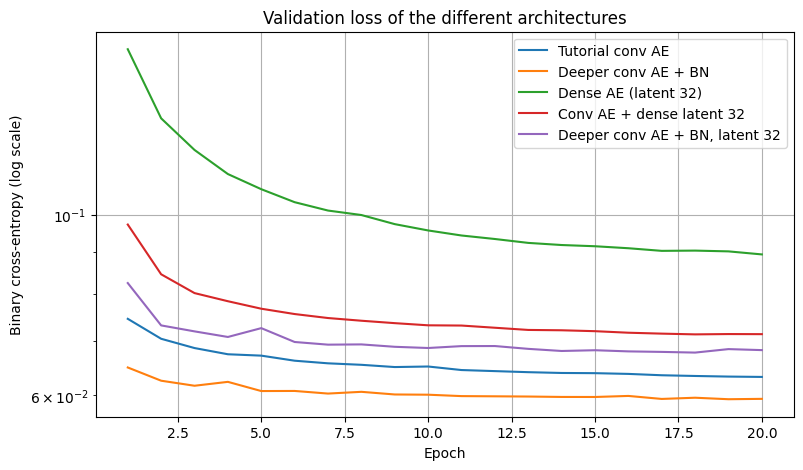

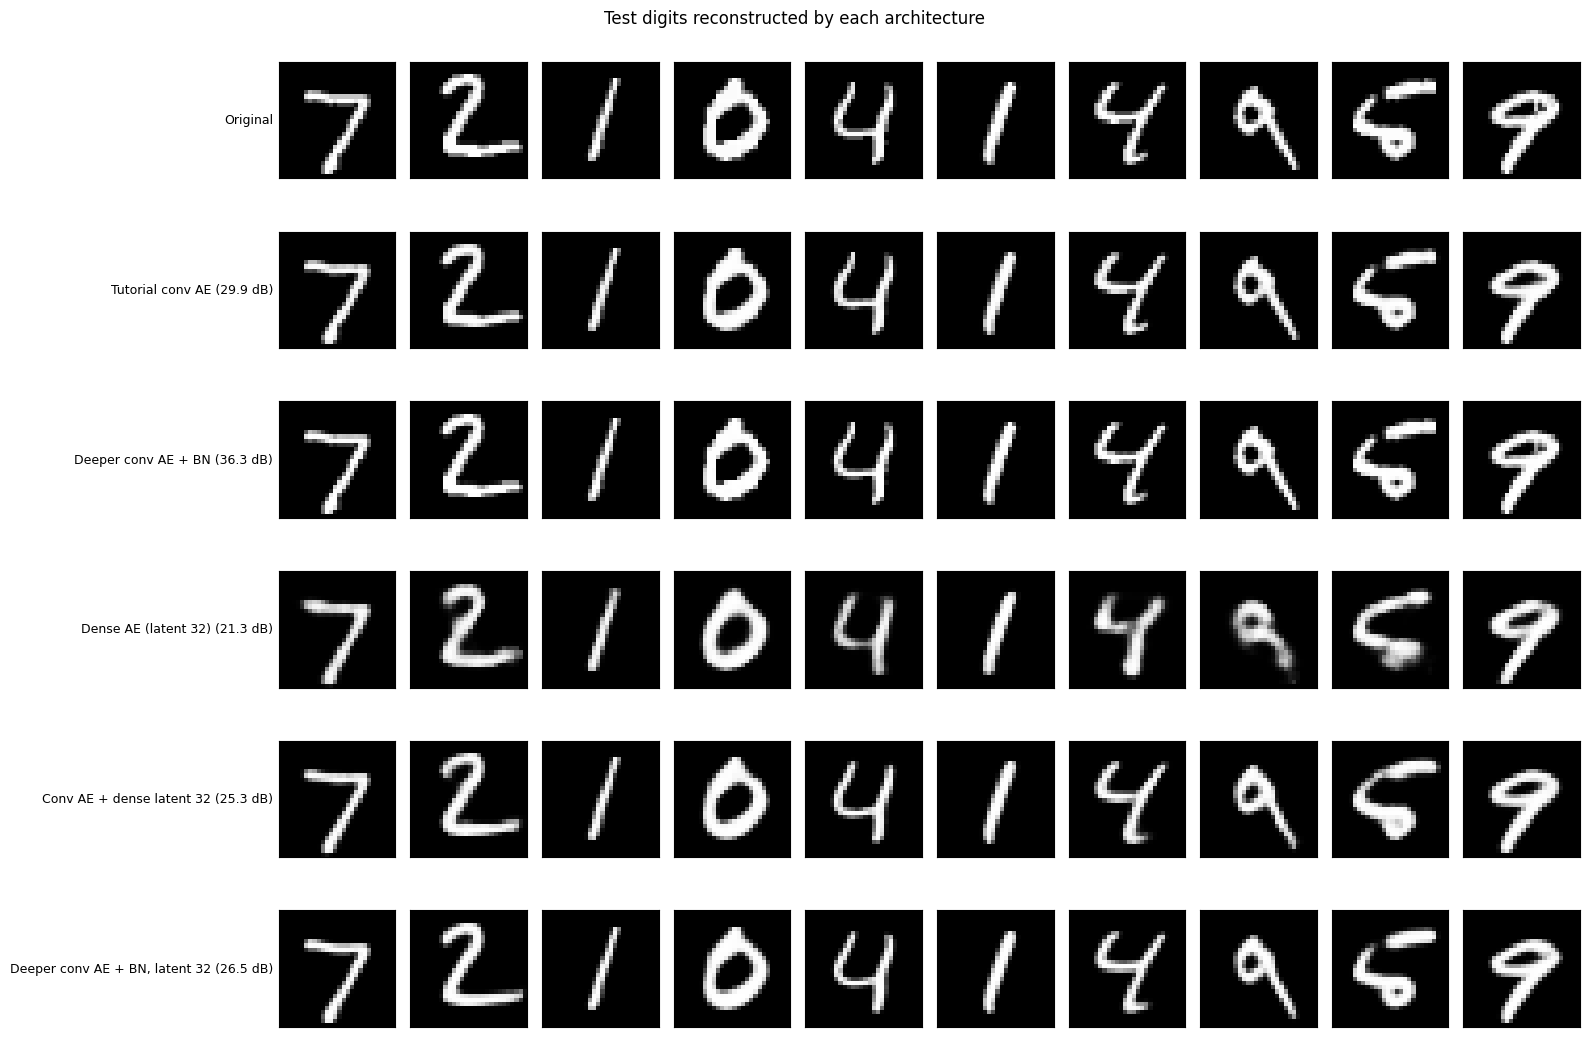

In [8]:
plt.figure(figsize=(9, 5))
for name, h in task_histories.items():
    plt.plot(range(1, TASK_EPOCHS + 1), h['val_loss'], label=name)
plt.yscale('log')
plt.title('Validation loss of the different architectures')
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy (log scale)')
plt.legend()
plt.grid()
plt.show()

idx = list(range(10))
names = list(task_models)
fig, axes = plt.subplots(len(names) + 1, len(idx), figsize=(16, 1.8 * (len(names) + 1)))
recon = {name: predict(task_models[name], x_test[idx]) for name in names}
for c, i in enumerate(idx):
    axes[0, c].imshow(x_test[i, 0], cmap='gray')
    for r, name in enumerate(names):
        axes[r + 1, c].imshow(recon[name][c, 0], cmap='gray', vmin=0, vmax=1)
for r, label in enumerate(['Original'] + [f"{n} ({task_results[n]['psnr']:.1f} dB)" for n in names]):
    for c in range(len(idx)):
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(label, rotation=0, ha='right', va='center', fontsize=9)
plt.suptitle('Test digits reconstructed by each architecture')
plt.tight_layout()
plt.show()

## Block 9: Task - Does the model really compress? Reconstructing random noise

Model                             MSE on digits  MSE on noise
Tutorial conv AE                        0.00118       0.11648
Deeper conv AE + BN                     0.00027       0.08737
Deeper conv AE + BN, latent 32          0.00276       0.27721


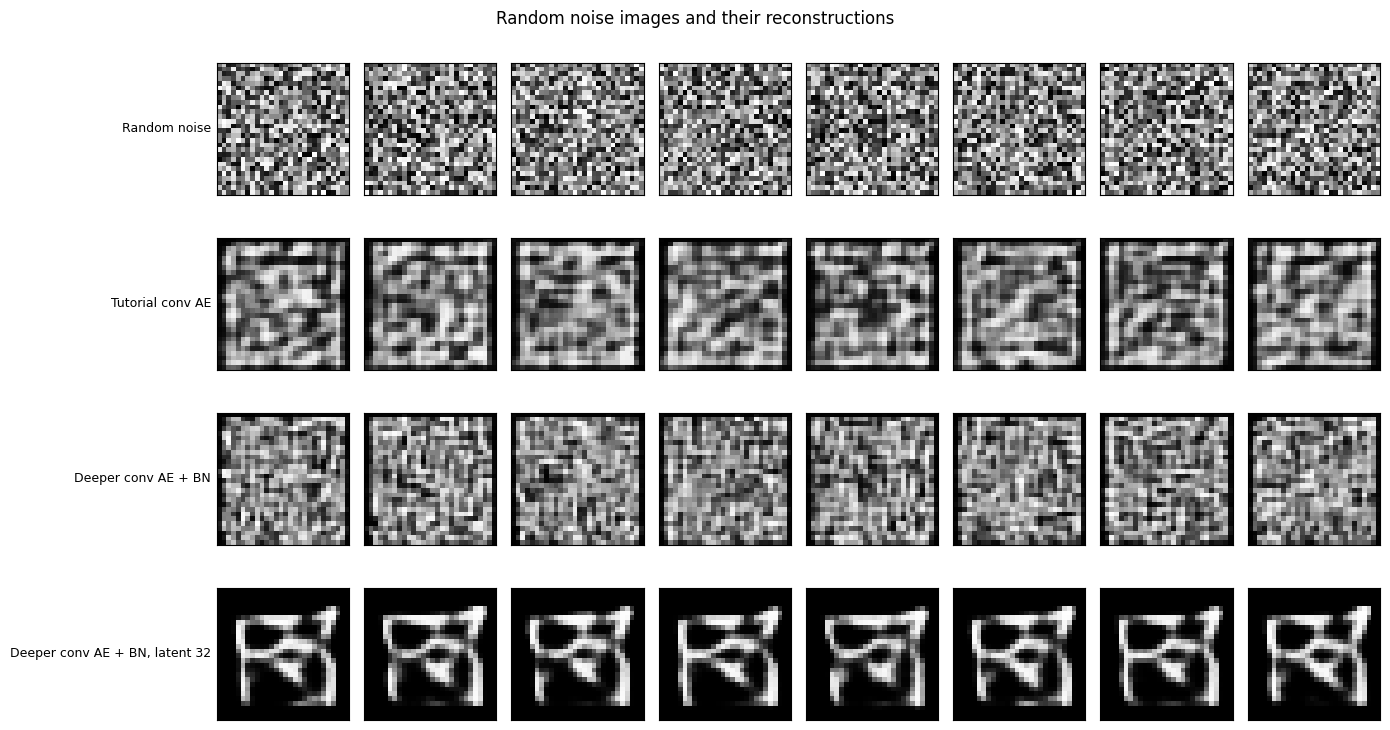

In [9]:
# A model with a real bottleneck can only rebuild what it has learned (digits).
# A model whose latent representation is larger than the input can copy almost anything.
set_seed(0)
noise = torch.rand(8, 1, 28, 28)
check = ['Tutorial conv AE', 'Deeper conv AE + BN', 'Deeper conv AE + BN, latent 32']
fig, axes = plt.subplots(len(check) + 1, 8, figsize=(14, 1.9 * (len(check) + 1)))
for c in range(8):
    axes[0, c].imshow(noise[c, 0], cmap='gray', vmin=0, vmax=1)
print(f"{'Model':32} {'MSE on digits':>14} {'MSE on noise':>13}")
for r, name in enumerate(check):
    out = predict(task_models[name], noise)
    for c in range(8):
        axes[r + 1, c].imshow(out[c, 0], cmap='gray', vmin=0, vmax=1)
    print(f"{name:32} {task_results[name]['mse']:14.5f} {((out - noise) ** 2).mean().item():13.5f}")
for r, label in enumerate(['Random noise'] + check):
    for c in range(8):
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(label, rotation=0, ha='right', va='center', fontsize=9)
plt.suptitle('Random noise images and their reconstructions')
plt.tight_layout()
plt.show()

## Block 10: Task - Effect of the latent size


Training: Deeper conv AE + BN, latent 2
Epoch 1/20 - loss: 0.2179 - val_loss: 0.1993
Epoch 5/20 - loss: 0.1881 - val_loss: 0.1875
Epoch 10/20 - loss: 0.1836 - val_loss: 0.1820
Epoch 15/20 - loss: 0.1805 - val_loss: 0.1803
Epoch 20/20 - loss: 0.1786 - val_loss: 0.1792
Test BCE: 0.1792 | MSE: 0.03953 | PSNR: 14.75 dB | time: 177.1 s

Training: Deeper conv AE + BN, latent 8
Epoch 1/20 - loss: 0.1477 - val_loss: 0.1191
Epoch 5/20 - loss: 0.1075 - val_loss: 0.1082
Epoch 10/20 - loss: 0.1030 - val_loss: 0.1067
Epoch 15/20 - loss: 0.1008 - val_loss: 0.1035
Epoch 20/20 - loss: 0.0994 - val_loss: 0.1023
Test BCE: 0.1023 | MSE: 0.01327 | PSNR: 19.86 dB | time: 177.1 s

Training: Deeper conv AE + BN, latent 128
Epoch 1/20 - loss: 0.1070 - val_loss: 0.0721
Epoch 5/20 - loss: 0.0654 - val_loss: 0.0650
Epoch 10/20 - loss: 0.0633 - val_loss: 0.0630
Epoch 15/20 - loss: 0.0624 - val_loss: 0.0628
Epoch 20/20 - loss: 0.0619 - val_loss: 0.0617
Test BCE: 0.0617 | MSE: 0.00089 | PSNR: 31.12 dB | time: 180.

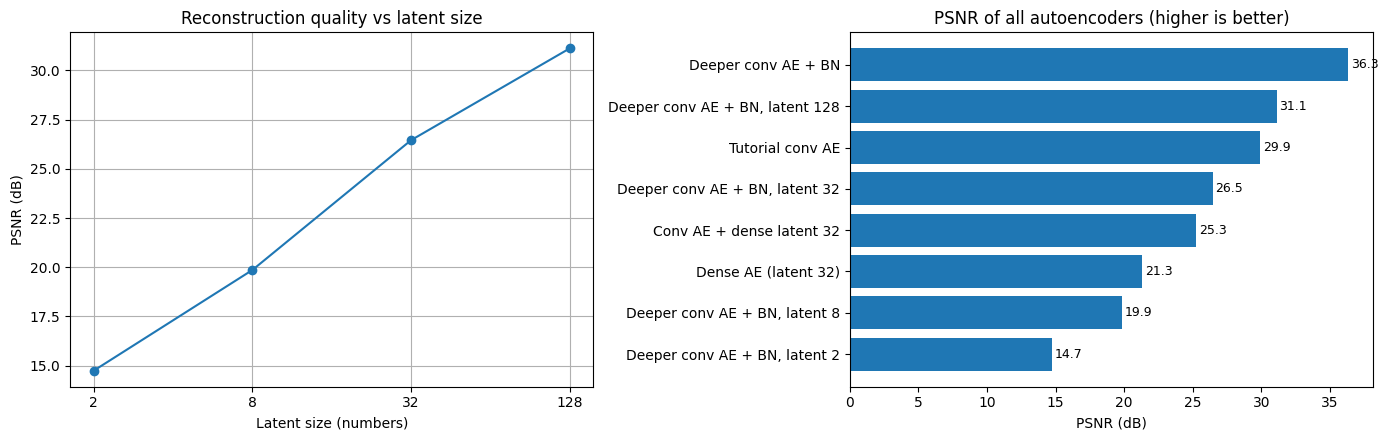

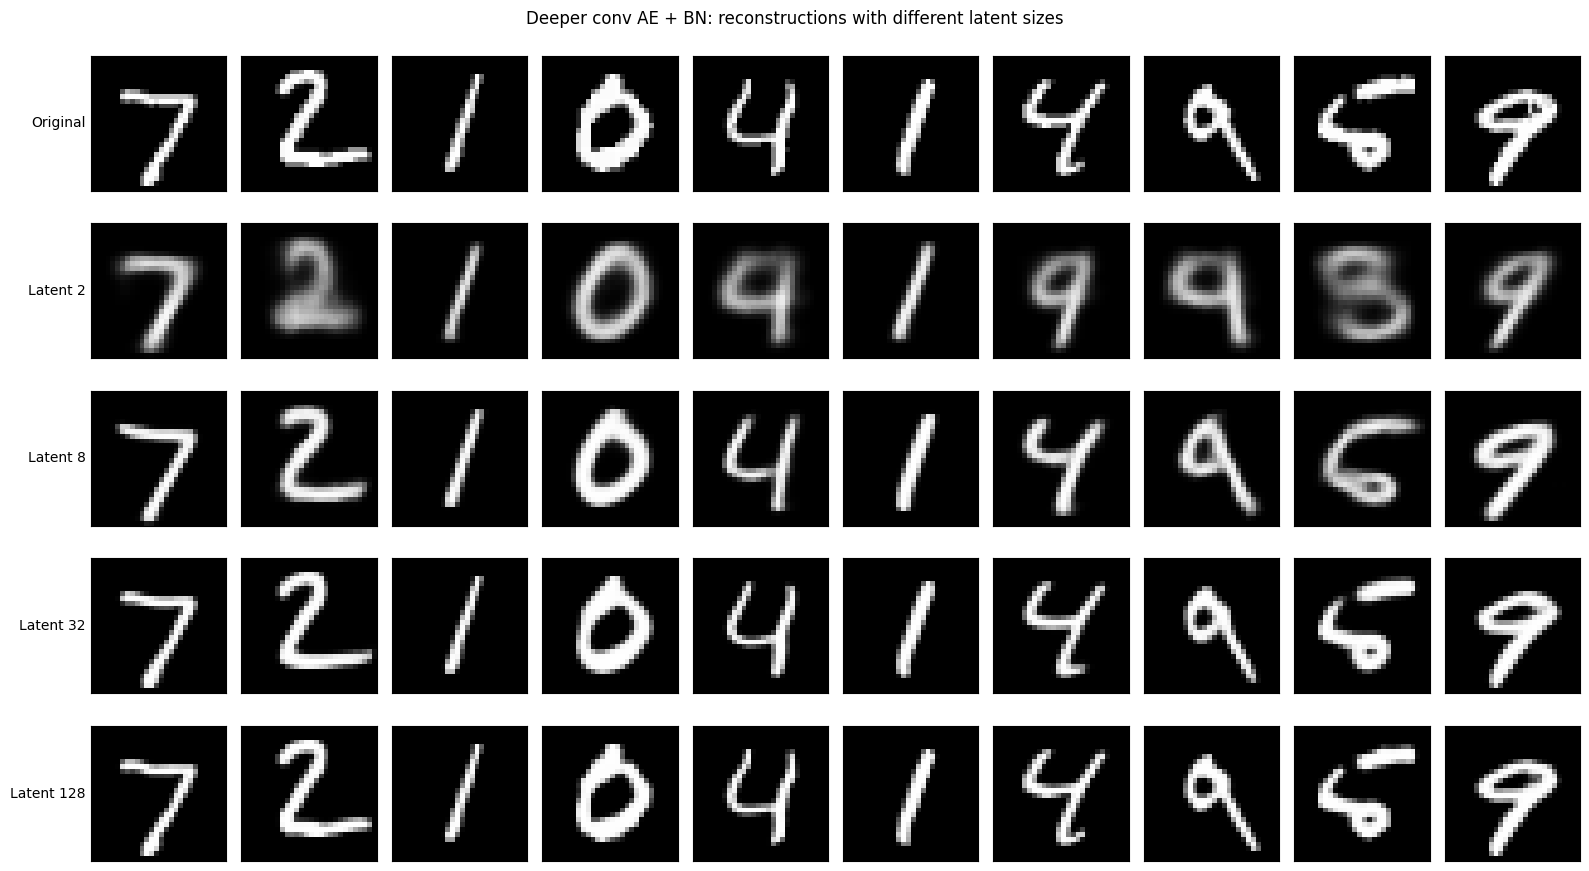

In [10]:
latent_sizes = [2, 8, 32, 128]
for d in latent_sizes:
    name = f'Deeper conv AE + BN, latent {d}'
    if name not in task_results:  # latent 32 was already trained above
        run(name, lambda d=d: DeepConvAE(d))

psnr = [task_results[f'Deeper conv AE + BN, latent {d}']['psnr'] for d in latent_sizes]
print(f"\n{'Latent size':>11} {'Compression':>12} {'MSE':>8} {'PSNR (dB)':>10}")
for d in latent_sizes:
    r = task_results[f'Deeper conv AE + BN, latent {d}']
    print(f"{d:11} {784 / d:11.0f}x {r['mse']:8.5f} {r['psnr']:10.2f}")

plt.figure(figsize=(14, 4.5))
plt.subplot(1, 2, 1)
plt.plot(latent_sizes, psnr, marker='o')
plt.xscale('log', base=2)
plt.xticks(latent_sizes, [str(d) for d in latent_sizes])
plt.title('Reconstruction quality vs latent size')
plt.xlabel('Latent size (numbers)')
plt.ylabel('PSNR (dB)')
plt.grid()

plt.subplot(1, 2, 2)
names = list(task_results)
order = np.argsort([task_results[n]['psnr'] for n in names])
plt.barh([names[i] for i in order], [task_results[names[i]]['psnr'] for i in order])
for k, i in enumerate(order):
    plt.text(task_results[names[i]]['psnr'] + 0.2, k, f"{task_results[names[i]]['psnr']:.1f}", va='center', fontsize=9)
plt.title('PSNR of all autoencoders (higher is better)')
plt.xlabel('PSNR (dB)')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(len(latent_sizes) + 1, 10, figsize=(16, 1.8 * (len(latent_sizes) + 1)))
for c in range(10):
    axes[0, c].imshow(x_test[c, 0], cmap='gray')
for r, d in enumerate(latent_sizes):
    out = predict(task_models[f'Deeper conv AE + BN, latent {d}'], x_test[:10])
    for c in range(10):
        axes[r + 1, c].imshow(out[c, 0], cmap='gray', vmin=0, vmax=1)
for r, label in enumerate(['Original'] + [f'Latent {d}' for d in latent_sizes]):
    for c in range(10):
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(label, rotation=0, ha='right', va='center', fontsize=10)
plt.suptitle('Deeper conv AE + BN: reconstructions with different latent sizes')
plt.tight_layout()
plt.show()